# Task 5 — Learned Density Ratio & Conditional Residual

ฝึกและบันทึกผลแล้ว ค่าเริ่มต้น Run All อ่านผลเดิม ไม่มีการ train ใหม่

ไม่มี anomaly labels จึงไม่มี offline macro F₃. Real-vs-shuffled AUC และ feature forecasting error เป็น auxiliary diagnostics ไม่ใช่ anomaly accuracy. Geometry/calibration ใช้ unlabeled cohort ร่วมกัน ส่วน classifiers/regressors ทำ cross-fitting


## 1. Setup


In [1]:
from pathlib import Path
import os, sys, json
import pandas as pd
import numpy as np
from IPython.display import display, Image
ROOT = next(candidate for base in (Path.cwd(), *Path.cwd().parents) for candidate in (base, base / "CPE342-Kaggle") if (candidate / "Task5/models/density_ratio_followup.py").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "Task5/cache/matplotlib"))
from Task5.models import density_ratio_followup as experiment
from Task5.models import conditional_residual_followup as residual
from Task5.models import report_density_ratio as report
OUT = experiment.OUT
print("Results:", OUT)
print("Scored source:", experiment.SOURCE)


Results: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task5/models/results/density_ratio_v1
Scored source: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/submission/kaggle_t12345_t1_slow800_bagging_v4_t3_conditional_quantile_v1_t4_resnet18_cosine18_tta_v1_t5_tail_engineered_v20.csv


## 2. Run / Resume or Read Saved Results


In [2]:
RUN_TRAINING = False
if RUN_TRAINING:
    from threadpoolctl import threadpool_limits
    with threadpool_limits(4):
        experiment.train_density()
        residual.run()
    report.generate()
else:
    print("Read saved results; training is disabled")
card = json.loads((OUT / "model_card.json").read_text())
print("Config:", card["config"])
print("Fraud labels available:", card["fraud_labels_available"])


Read saved results; training is disabled
Config: {'folds': 5, 'bags': 3, 'projections': 140, 'iterations': 160, 'training_null_repeats': 3, 'evaluation_null_repeats': 2, 'seed': 342, 'threads': 4, 'max_bins': 63, 'learning_rate': 0.07, 'max_depth': 5, 'l2_regularization': 2.0}
Fraud labels available: False


## 3. Preprocessing, Within-account Change and Univariate Density Modes


,family,log1p_transform
0,accuracy_mean,True
1,accuracy_std,True
2,activity_level,True
3,communication_frequency,True
4,currency_transfers,True
5,device_count,False
6,friend_adds,True
7,friend_removes,True
8,guild_changes,False
9,ip_hash_entropy,False


,view,positive_posterior_rows,posterior_above_half_rows,posterior_mean
0,shift_probability,810,810,0.03119
1,island_probability,981,981,0.03789
2,dependence_probability,522,219,0.00913


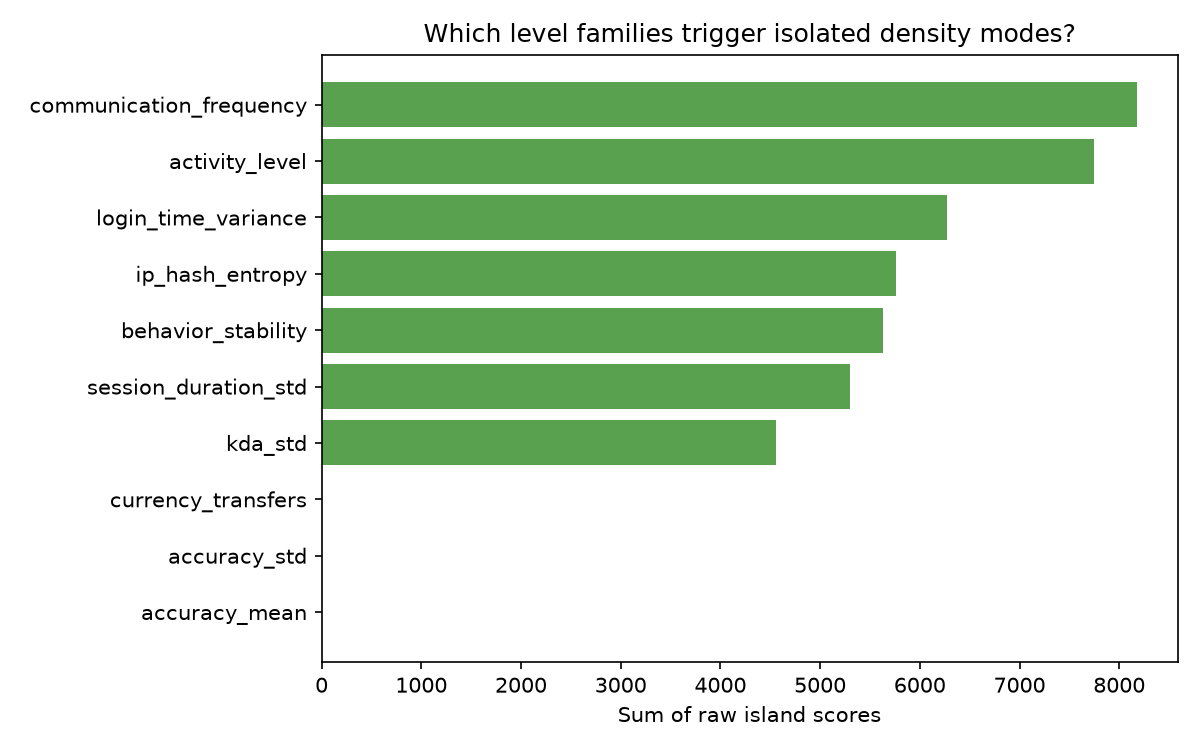

In [3]:
display(pd.read_csv(OUT / "family_transform_choices.csv"))
display(pd.read_csv(OUT / "view_summary.csv").round(5))
display(Image(filename=str(OUT / "figures/island_attribution.png")))


## 4. Cross-feature Dependence — Real-vs-Shuffled Classifiers

AUC ในตารางนี้วัดแยก background จริงจาก shuffled-null ไม่ใช่ตรวจ anomaly


In [4]:
training_log = pd.read_csv(OUT / "density_training_log.csv")
display(training_log.drop(columns="auc_note").round(5))
print("Auxiliary real-vs-shuffled AUC mean:", training_log.real_vs_shuffled_holdout_auc.mean())
print("Total fold fit seconds:", training_log.seconds.sum())


Auxiliary real-vs-shuffled AUC mean: 0.5086091636684564
Total fold fit seconds: 21.255993124563247


,bag,fold,fit_background_rows,scored_rows,real_vs_shuffled_holdout_auc,seconds
0,1,1,19281,5178,0.51465,1.43814
1,1,2,19258,5178,0.50382,1.37546
2,1,3,19284,5178,0.50788,1.37334
3,1,4,19288,5178,0.50001,1.43625
4,1,5,19281,5177,0.51417,1.44630
5,2,1,19281,5178,0.50612,1.31158
6,2,2,19258,5178,0.50977,1.36095
7,2,3,19284,5178,0.50999,1.37341
8,2,4,19288,5178,0.51182,1.51654
9,2,5,19281,5177,0.51374,1.58468


## 5. Operating Policy and Alert Count

ใช้ model-based posterior เลือก operating count ด้วย plug-in expected-count objective; ไม่ใช่ F₃ ที่วัดด้วย labels. Control คง 6,531 alerts เพื่อแยกผล ranking จาก budget


,model_based_policy
positive_count,2046.000000
estimated_prevalence,0.077951
posterior_cutoff,0.258080
fixed_budget_control,6531.000000


,candidate,alerts,fraction,shared_with_scored_tail,added_alerts,removed_alerts,changed_rows,jaccard_vs_tail
0,density_auto,2046,0.07903,1686,360,4845,5205,0.24467
1,density_fixed6531,6531,0.25227,2801,3730,3730,7460,0.27298


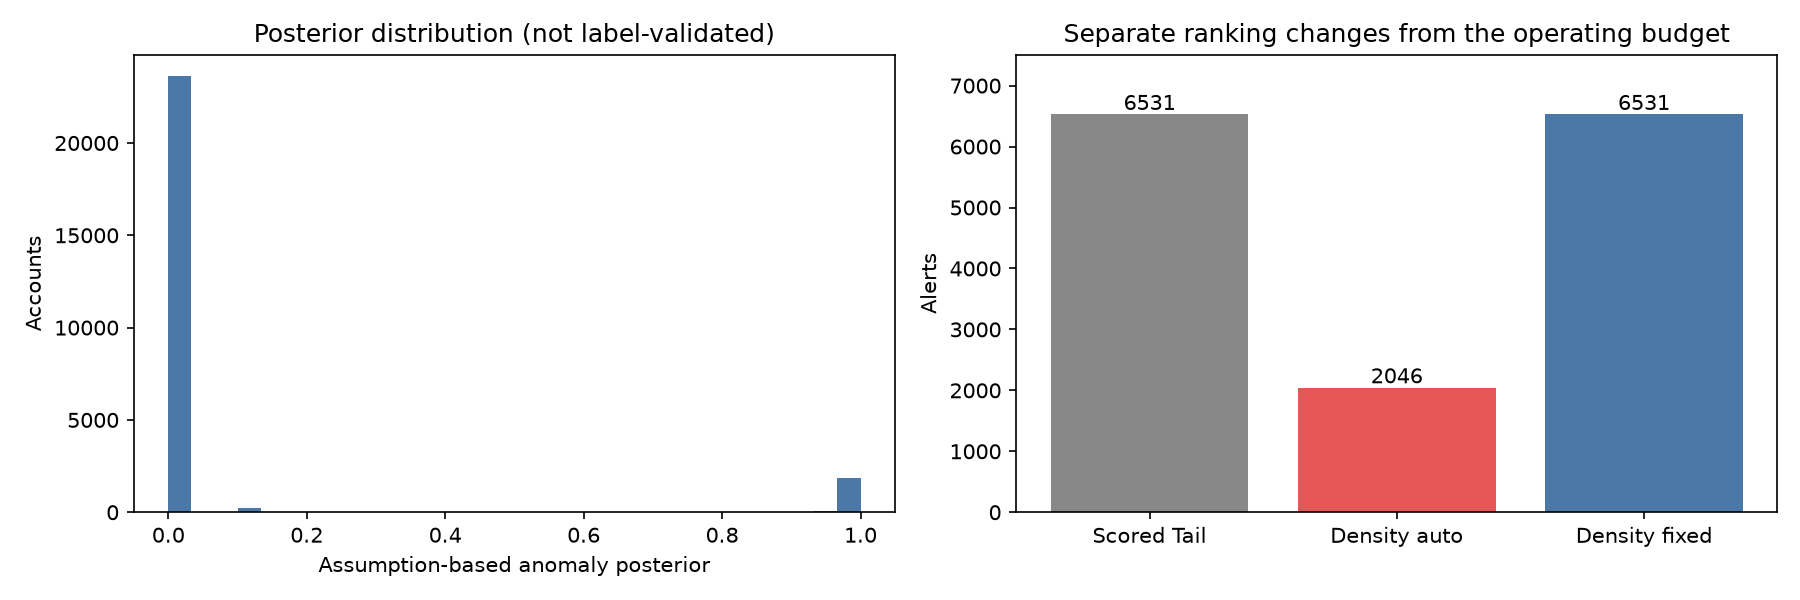

In [5]:
policy = json.loads((OUT / "operating_policy.json").read_text())
display(pd.Series({k: policy[k] for k in ["positive_count", "estimated_prevalence", "posterior_cutoff", "fixed_budget_control"]}).to_frame("model_based_policy"))
display(pd.read_csv(OUT / "candidate_comparison.csv").round(5))
display(Image(filename=str(OUT / "figures/posterior_and_budget.png")))


## 6. Conditional Residual — Diagnostic Only

ใช้ข้อมูลช่วง 1–3 ทำนาย feature ช่วง 4 ของคนละ fold เป้าหมายเป็น feature values ไม่ใช่ fraud labels. ไม่ผสม residual score เข้าตัวหลักโดยไม่มีหลักฐาน


,diagnostic
role,diagnostic only; no submitted candidate and no...
crossfit_models,50
feature_targets,"[skill_rating, skill_trajectory, currency_tran..."
input_features,137
score_spearman_with_density,0.287413
same_count_alert_jaccard_with_density,0.359017
matched_alert_count,2046
macro_f3,None
metric_note,Forecast targets are raw observed feature valu...


,center,scale,observed_rows,feature_forecast_mae_signed_log_units
skill_rating,0.00004,0.03399,24614.0,0.03766
skill_trajectory,-0.00016,0.11896,24581.0,0.15488
currency_transfers,-0.00072,0.12005,24672.0,0.11646
purchase_amount_mean,-0.00065,0.12672,24679.0,0.10807
communication_frequency,-0.00025,0.04955,24601.0,0.04102
friend_adds,-0.00021,0.13861,24670.0,0.12562
friend_removes,-0.00004,0.07546,24654.0,0.09290
device_count,-0.00000,0.21962,24717.0,0.17643
login_count,-0.00022,0.12133,24654.0,0.09499
reaction_time_mean,0.00022,0.06453,24657.0,0.05398


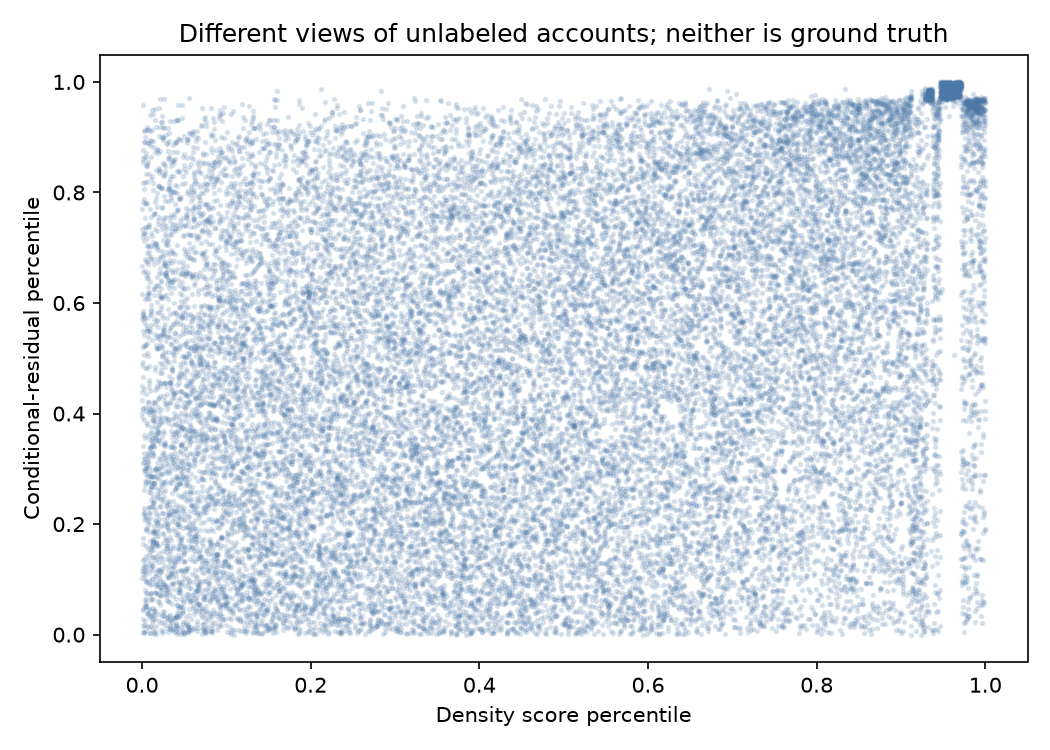

In [6]:
diagnostic = json.loads((residual.OUT / "summary.json").read_text())
display(pd.Series(diagnostic).to_frame("diagnostic"))
display(pd.DataFrame(json.loads((residual.OUT / "normalizers.json").read_text())).T.round(5))
display(Image(filename=str(OUT / "figures/conditional_residual_comparison.png")))


## 7. Sensitivity — Not a Model Quality Ranking


In [7]:
display(pd.read_csv(OUT / "view_ablation_diagnostics.csv").drop(columns="note").round(5))
display(pd.read_csv(OUT / "bag_sensitivity.csv").round(5))


,diagnostic_ablation,auto_alerts,estimated_prevalence,jaccard_vs_primary
0,shift_only,810,0.03119,0.39589
1,island_only,981,0.03789,0.47947
2,shift_and_island,1791,0.06909,0.87537
3,prespecified_three_view,2046,0.07795,1.00000


,omitted_bag,auto_alerts,jaccard_vs_primary,estimated_prevalence
0,1,2062,0.97121,0.07785
1,2,2264,0.87800,0.07729
2,3,2253,0.90137,0.07959


## 8. Accounts Changed Relative to Scored Tail


,group,rows,missing_count,security_flag_count,shift_probability,island_probability,dependence_probability,conditional_residual_score
0,shared_alert,1686,6.0,0.0,0.0,0.00000,0.0,2.25837
1,added_alert,360,6.0,0.0,0.0,0.99989,0.0,1.74587
2,removed_alert,4845,6.0,0.0,0.0,0.00000,0.0,1.71457
3,shared_nonalert,18998,6.0,0.0,0.0,0.00000,0.0,1.69416


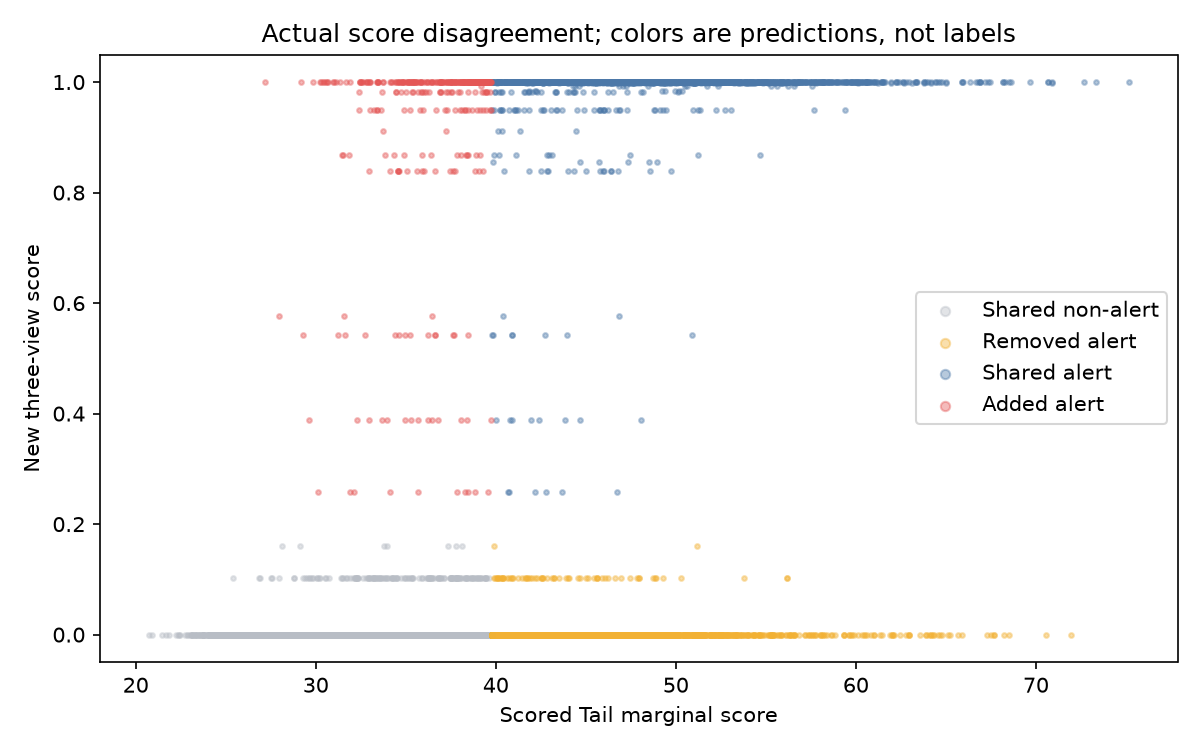

In [8]:
profiles = pd.read_csv(OUT / "discordance_profiles.csv")
display(profiles[["group", "rows", "missing_count", "security_flag_count", "shift_probability", "island_probability", "dependence_probability", "conditional_residual_score"]].round(5))
display(Image(filename=str(OUT / "figures/tail_vs_density.png")))


## 9. Saved Artifact Verification


In [9]:
proof = json.loads((OUT / "verification.json").read_text())
display(pd.Series(proof).to_frame("verified"))
assert proof["density_fold_models_checked"] == 15
assert proof["conditional_forecast_models_checked"] == 50
assert proof["primary_decisions_recomputed"] == 25889


,verified
raw_rows,25889
density_fold_models_checked,15
density_heldout_predictions_recomputed,77667
null_logits_recomputed,144588
conditional_forecast_models_checked,50
conditional_forecasts_recomputed,258890
primary_decisions_recomputed,25889
primary_alerts,2046
control_alerts,6531
no_scored_row_in_its_learned_fit,True


## 10. Predictions and Combined Submissions

Both combined candidates preserve IDs/Tasks1–4 from the scored 0.75893 source. They retain the old Task2 column. Neither candidate has a Kaggle score yet


In [10]:
for name in ["density_auto", "density_fixed6531"]:
    pred = pd.read_parquet(OUT / f"{name}_predictions.parquet")
    assert len(pred) == 25889 and pred.player_id.is_unique and pred.id.is_unique
    assert pred.task5.isin([0,1]).all()
    print(name, "alerts:", int(pred.task5.sum()))
    combined = experiment.SOURCE.with_name(experiment.SOURCE.name.replace("tail_engineered_v20", name + "_v1"))
    print("Combined:", combined)
    display(pred.head())


density_auto alerts: 2046
Combined: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/submission/kaggle_t12345_t1_slow800_bagging_v4_t3_conditional_quantile_v1_t4_resnet18_cosine18_tta_v1_t5_density_auto_v1.csv
density_fixed6531 alerts: 6531
Combined: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/submission/kaggle_t12345_t1_slow800_bagging_v4_t3_conditional_quantile_v1_t4_resnet18_cosine18_tta_v1_t5_density_fixed6531_v1.csv


,test_row_index,player_id,id,task5,ranking_score,model_anomaly_posterior
0,0,P024743,ANS00001,1,0.999894,0.999894
1,1,P005319,ANS00002,0,0.000002,0.000000
2,2,P014970,ANS00003,1,0.999905,1.000000
3,3,P003275,ANS00004,0,0.000002,0.000000
4,4,P009022,ANS00005,0,0.000002,0.000000


,test_row_index,player_id,id,task5,ranking_score,model_anomaly_posterior
0,0,P024743,ANS00001,1,0.999894,0.999894
1,1,P005319,ANS00002,0,0.000002,0.000000
2,2,P014970,ANS00003,1,0.999905,1.000000
3,3,P003275,ANS00004,0,0.000002,0.000000
4,4,P009022,ANS00005,0,0.000002,0.000000
